# Tutorial: Generic CSV Boxplot

This notebook reads a long-format CSV and creates two matching boxplots: one with slightly jittered observations and one without them.

You choose the CSV path, the label/category column, the y-value column, and both axis titles manually.

## Expected CSV layout

Each row should represent one observation. The file must contain at least one categorical label column and one numeric value column. Other columns are allowed and are ignored unless selected.

| group | value | replicate_id |
|---|---:|---|
| Control | 12.4 | R1 |
| Treatment A | 15.1 | R2 |
| Treatment B | 18.7 | R3 |

## Outline

1. Load and inspect the CSV.
2. Manually choose the label and y-value columns.
3. Manually enter the axis titles.
4. Generate and compare the two boxplots.

In [11]:
from pathlib import Path
import importlib.util
import sys

import pandas as pd
from IPython.display import display

NOTEBOOK_DIR = Path.cwd()
SCRIPT_PATH = NOTEBOOK_DIR / 'visualize_boxplot.py'

if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f'Could not find {SCRIPT_PATH}. Open this notebook from the boxplot folder.'
    )

CSV_INPUT = input('Enter the CSV filename or path: ').strip()
if not CSV_INPUT:
    raise ValueError('A CSV filename or path is required.')
CSV_PATH = Path(CSV_INPUT).expanduser()
if not CSV_PATH.is_absolute():
    CSV_PATH = NOTEBOOK_DIR / CSV_PATH
if not CSV_PATH.exists():
    raise FileNotFoundError(f'Could not find {CSV_PATH}.')

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

MODULE_SPEC = importlib.util.spec_from_file_location('visualize_boxplot', SCRIPT_PATH)
if MODULE_SPEC is None or MODULE_SPEC.loader is None:
    raise ImportError(f'Could not load {SCRIPT_PATH}.')
visualize_boxplot = importlib.util.module_from_spec(MODULE_SPEC)
MODULE_SPEC.loader.exec_module(visualize_boxplot)

print(f'Data file: {CSV_PATH.name}')
print(f'Plot script: {SCRIPT_PATH.name}')

Data file: blood_glucose_meal_response_synthetic.csv
Plot script: visualize_boxplot.py


## Step 1 - Inspect the data

In [12]:
data = visualize_boxplot.load_boxplot_csv(CSV_PATH)
print(f'Rows: {len(data)}')
print(f'Available columns: {list(data.columns)}')
display(data.head())

Rows: 80
Available columns: ['observation_id', 'participant_id', 'meal_type', 'meal_description', 'glucose_2h_mg_dL', 'synthetic_outlier_flag', 'data_status']


,observation_id,participant_id,meal_type,meal_description,glucose_2h_mg_dL,synthetic_outlier_flag,data_status
0,OBS001,P001,Oatmeal breakfast,rolled oats with berries,112,False,synthetic_demo_data
1,OBS002,P002,Oatmeal breakfast,rolled oats with berries,118,False,synthetic_demo_data
2,OBS003,P003,Oatmeal breakfast,rolled oats with berries,121,False,synthetic_demo_data
3,OBS004,P004,Oatmeal breakfast,rolled oats with berries,115,False,synthetic_demo_data
4,OBS005,P005,Oatmeal breakfast,rolled oats with berries,127,False,synthetic_demo_data


## Step 2 - Select columns and titles

Enter the exact column names from the CSV. Then enter the titles you want to appear on the x-axis and y-axis. Press Enter at a title prompt to use the selected column name.

In [13]:
category_column = input('Enter the label/category column name exactly: ').strip()
value_column = input('Enter the y-value column name exactly: ').strip()

category_column, value_column = visualize_boxplot.choose_columns(
    data,
    category_column=category_column,
    value_column=value_column,
)

category_title = input(
    'Enter the x-axis title (press Enter to use the column name): '
).strip() or category_column
value_title = input(
    'Enter the y-axis title (press Enter to use the column name): '
).strip() or value_column

print(f'Label/category column: {category_column}')
print(f'Y-value column: {value_column}')
print(f'X-axis title: {category_title}')
print(f'Y-axis title: {value_title}')

Label/category column: meal_type
Y-value column: glucose_2h_mg_dL
X-axis title: Meal type
Y-axis title: Glucose response (mg/dL)


## Step 3 - Generate both plots

Both plots use the same data, column selections, colors, font settings, line weights, and axis limits. The only difference is whether the individual observations are overlaid.

In [14]:
plot_data = visualize_boxplot.validate_boxplot_data(
    data, category_column, value_column
)
OUTPUT_WITH_POINTS, OUTPUT_WITHOUT_POINTS = visualize_boxplot.derive_output_paths(CSV_PATH)

# None keeps the order in which groups first appear in the CSV.
# Example: group_order = ['Oatmeal breakfast', 'White-bread breakfast']
group_order = None

visualize_boxplot.create_boxplot(
    frame=plot_data,
    category_column=category_column,
    value_column=value_column,
    category_title=category_title,
    value_title=value_title,
    output_path=OUTPUT_WITH_POINTS,
    title=None,
    group_order=group_order,
    show_points=True,
    show=False,
)

visualize_boxplot.create_boxplot(
    frame=plot_data,
    category_column=category_column,
    value_column=value_column,
    category_title=category_title,
    value_title=value_title,
    output_path=OUTPUT_WITHOUT_POINTS,
    title=None,
    group_order=group_order,
    show_points=False,
    show=False,
)

print(f'Saved: {OUTPUT_WITH_POINTS.name}')
print(f'Saved: {OUTPUT_WITHOUT_POINTS.name}')

Saved: blood_glucose_meal_response_synthetic_boxplot_with_points.png
Saved: blood_glucose_meal_response_synthetic_boxplot_without_points.png


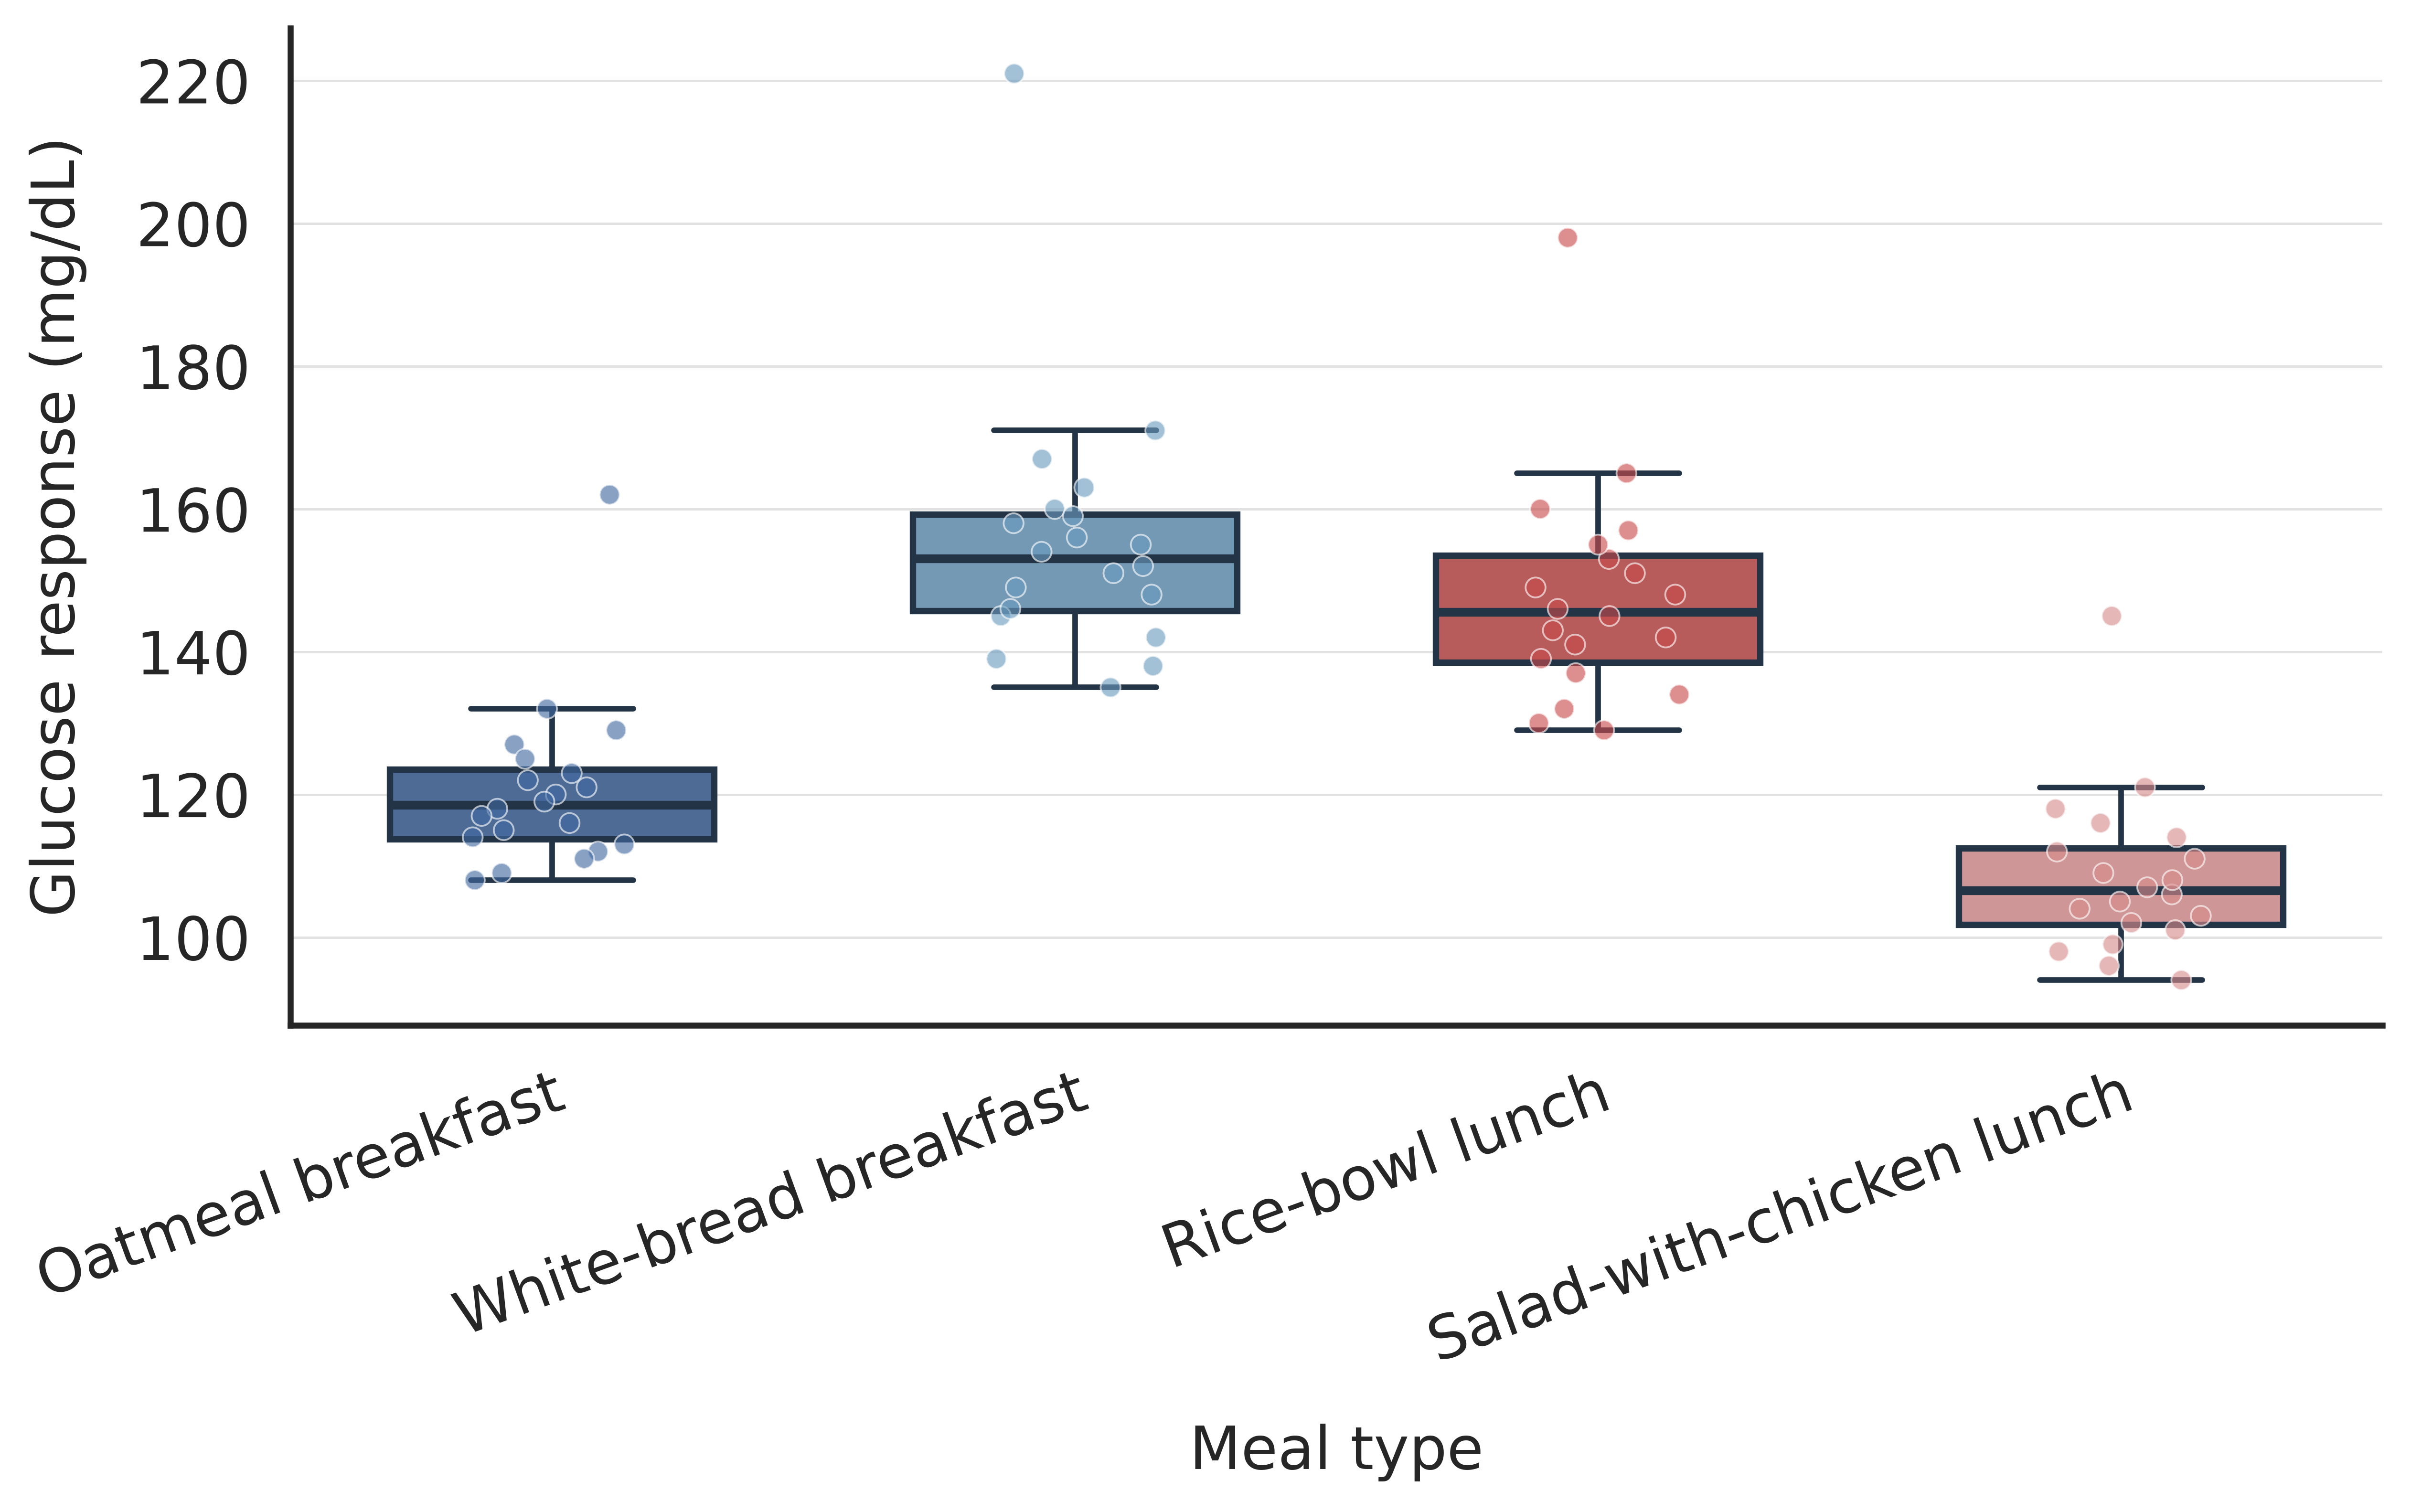

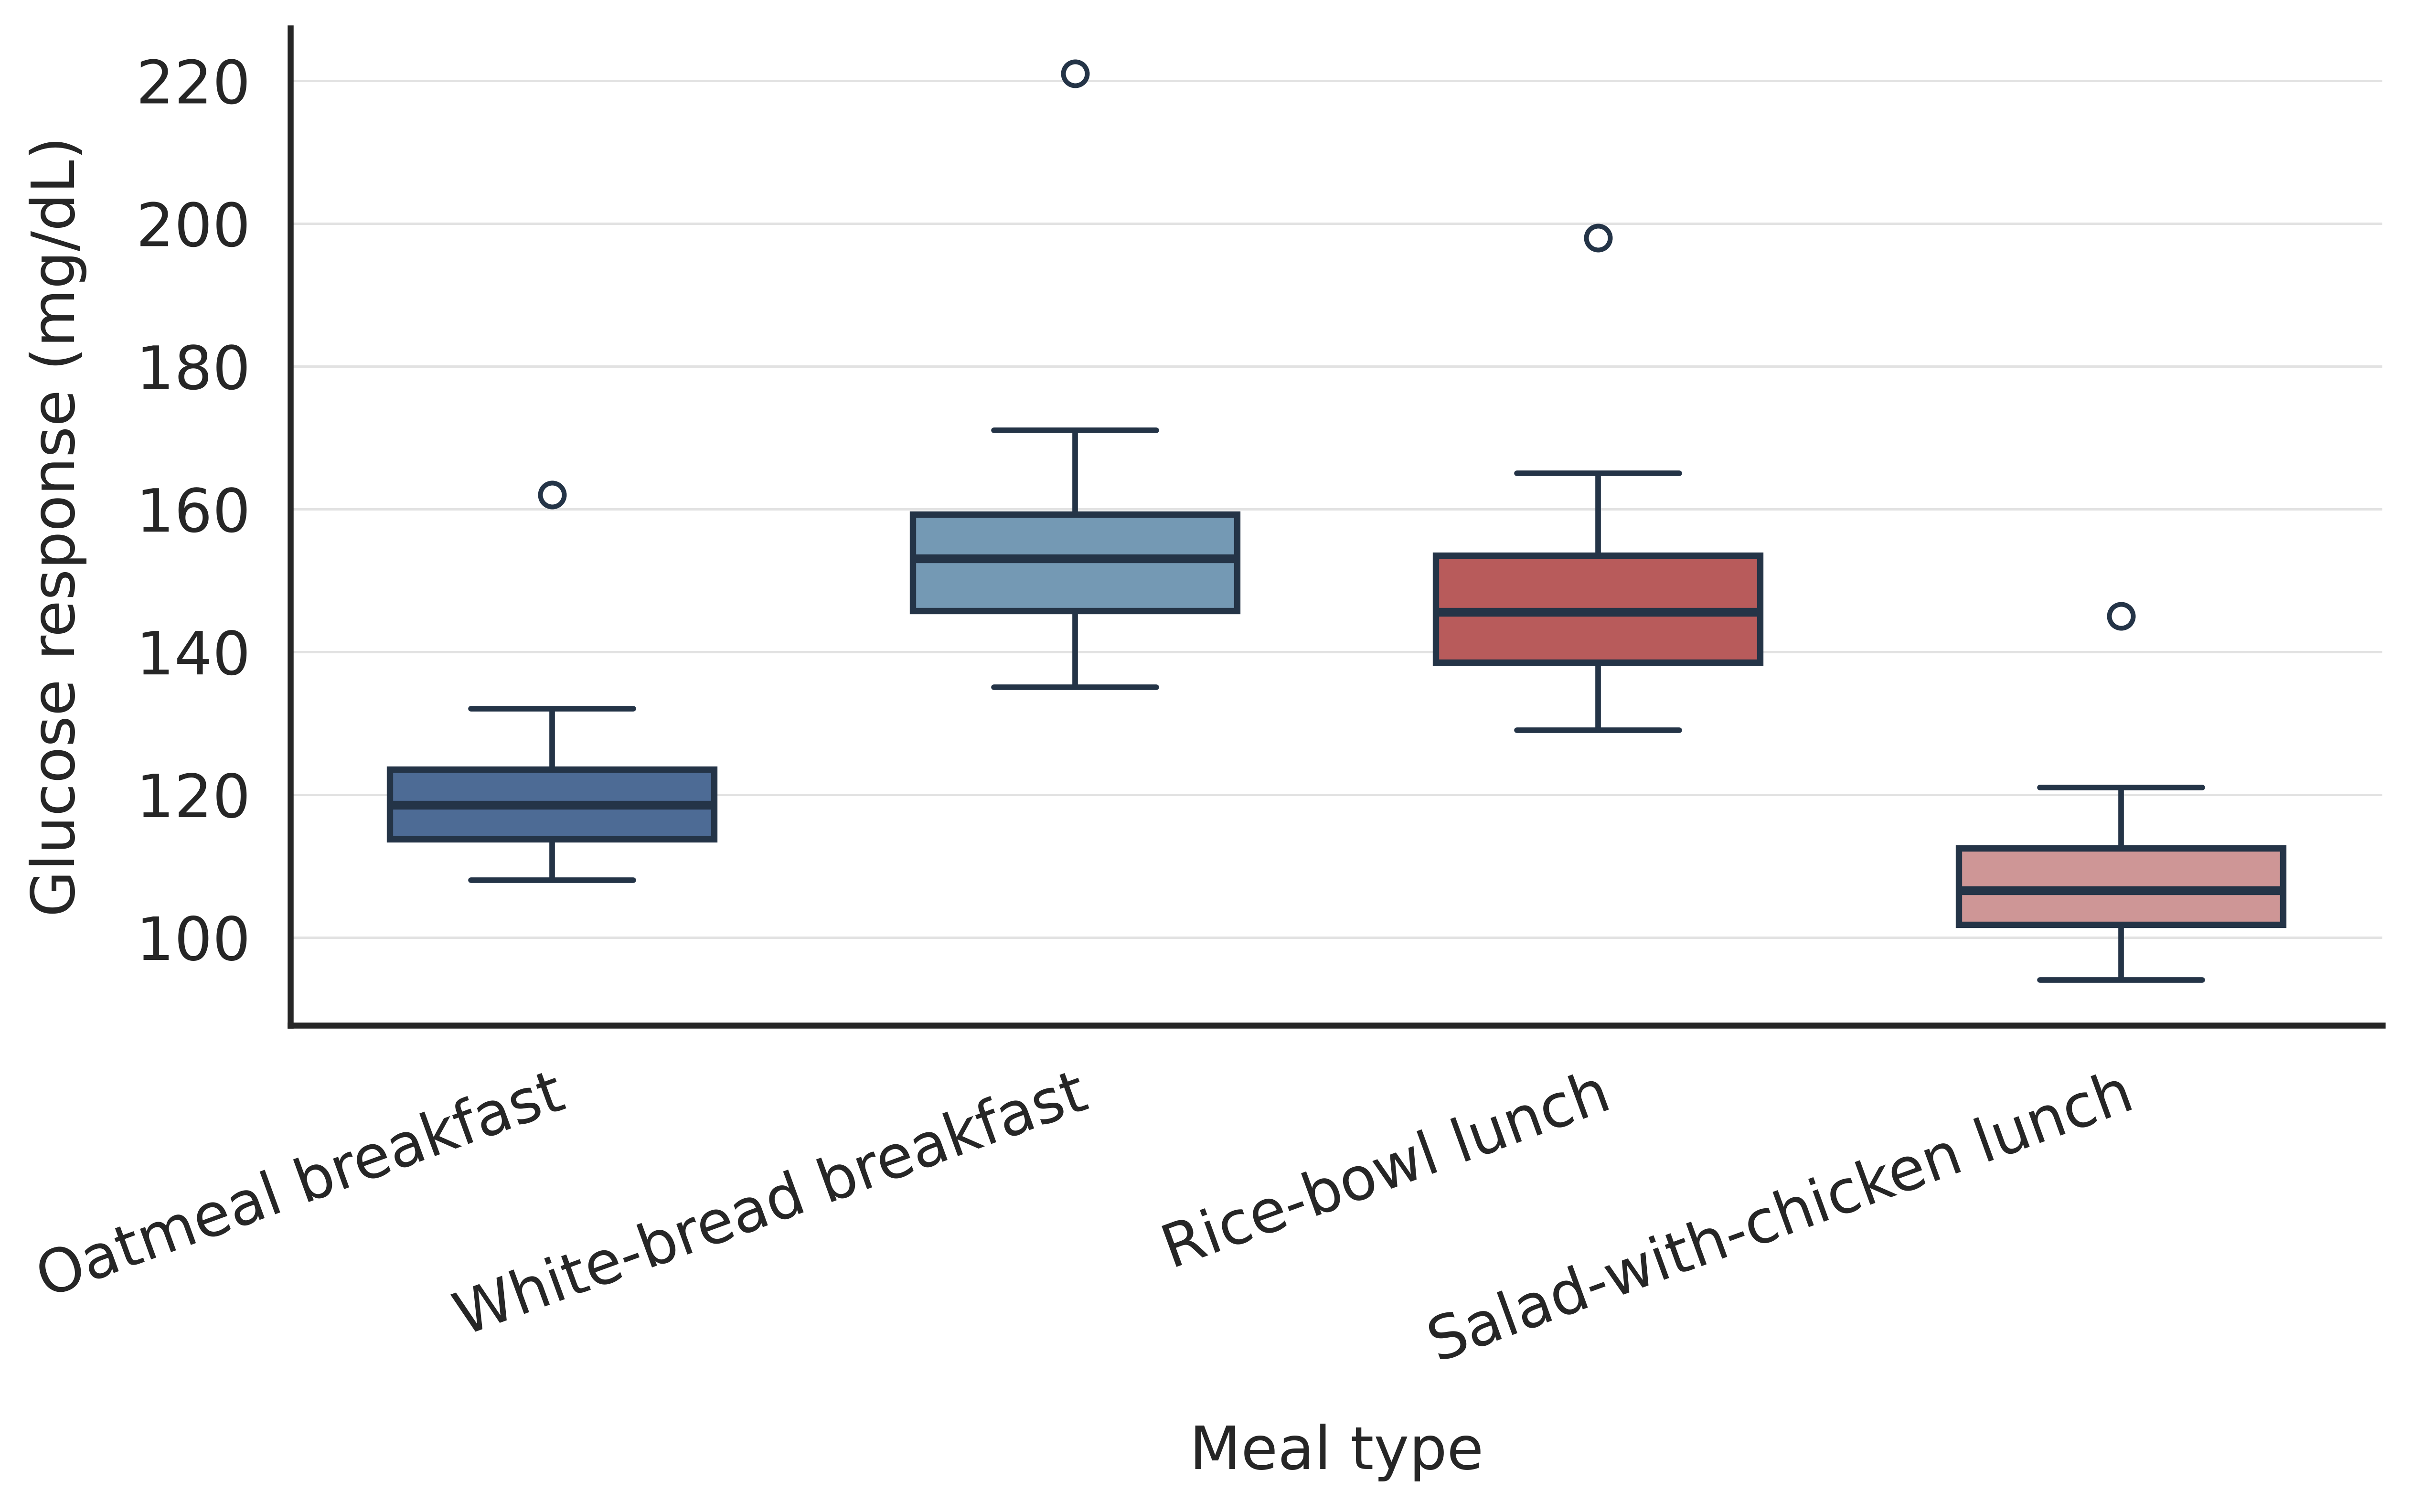

In [15]:
from IPython.display import Image, display

display(Image(filename=str(OUTPUT_WITH_POINTS)))
display(Image(filename=str(OUTPUT_WITHOUT_POINTS)))

## Interpretation

- The line inside each box is the median.
- The box spans the middle 50% of observations (the interquartile range, IQR).
- Whiskers extend to the most extreme observations within 1.5 × IQR of the box.
- In the plot without observations, values beyond the whiskers are drawn as open circles (outliers), so they are never hidden.
- The first plot shows every raw observation, including the outliers; the second emphasizes the distribution summary.
- Groups follow the order in which they first appear in the CSV unless you set `group_order`.

In [16]:
plot_data.groupby(category_column)[value_column].agg(
    count='count',
    median='median',
    mean='mean'
).round(2)

,count,median,mean
meal_type,,,
Oatmeal breakfast,20,118.5,120.65
Rice-bowl lunch,20,145.5,147.70
Salad-with-chicken lunch,20,106.5,108.45
White-bread breakfast,20,153.0,155.45


## Common pitfalls

- Select a categorical label column for the x-axis, not an identifier with a unique value in every row.
- Select a numeric column for the y-axis; the script reports invalid CSV rows if conversion fails.
- Enter measurement units in the custom y-axis title when needed.
- Use `group_order` when the CSV order is not the order you want to present.